# 3.2 TF-IDF caractères + SVM : testé sur les 3 corpus OCR

Cette fois on entraîne un classifieur : un SVM linéaire (`LinearSVC`, fait pour les grands vecteurs du
TF-IDF), avec C choisi par validation croisée. Même pipeline sur le dataset 1 et les deux extraits du
dataset 2 (commentés en 4.2).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import LinearSVC

CORPUS_OCR = {
    "dataset 1": "../data/artifacts_document-classification-dataset_1/ocr_corpus.csv",
    "dataset 2 (30 000 images)": "../data/artifacts_rvl_cdip_filtered_dataset_2/ocr_corpus.csv",
    "dataset 2 (60 000 images)": "../data/artifacts_rvl_cdip_filtered_dataset_3/ocr_corpus.csv",
}

## Même pipeline sur les 3 corpus

In [2]:
lignes, rapports = [], {}
for nom, fichier in CORPUS_OCR.items():
    corpus = pd.read_csv(fichier, keep_default_na=False)
    corpus = corpus[corpus["text"] != ""]

    train, test = train_test_split(corpus, test_size=0.2, random_state=42, stratify=corpus["label"])
    vectoriseur = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
    X_train = vectoriseur.fit_transform(train["text"])
    X_test = vectoriseur.transform(test["text"])

    grid = GridSearchCV(LinearSVC(max_iter=5000, random_state=42),
                        {"C": [0.01, 0.1, 0.3, 1, 3, 10]}, cv=5, n_jobs=-1)
    grid.fit(X_train, train["label"])
    y_pred = grid.predict(X_test)

    lignes.append({"corpus": nom, "classes": corpus["label"].nunique(), "train": len(train),
                   "test": len(test), "meilleur C": grid.best_params_["C"],
                   "accuracy": accuracy_score(test["label"], y_pred)})
    rapports[nom] = classification_report(test["label"], y_pred, digits=3)

tableau = pd.DataFrame(lignes)
tableau.round(3)

,corpus,classes,train,test,meilleur C,accuracy
0,dataset 1,3,132,33,0.1,0.939
1,dataset 2 (30 000 images),6,1437,360,0.3,0.844
2,dataset 2 (60 000 images),6,9572,2394,1.0,0.867


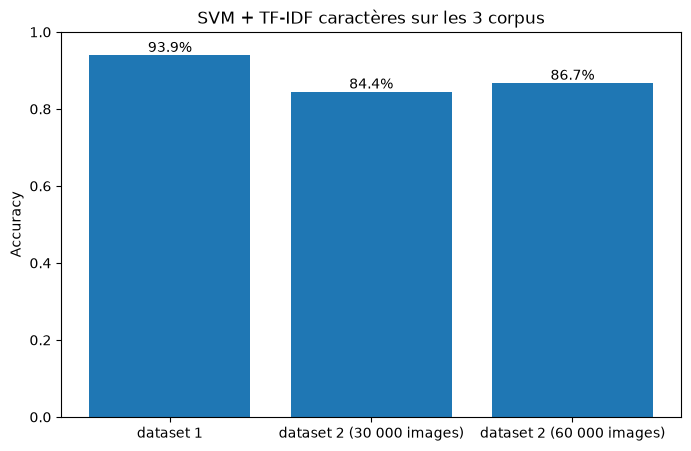

In [3]:
plt.figure(figsize=(8, 5))
barres = plt.bar(tableau["corpus"], tableau["accuracy"])
plt.bar_label(barres, labels=[f"{acc:.1%}" for acc in tableau["accuracy"]])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("SVM + TF-IDF caractères sur les 3 corpus")
plt.show()

## Rapport détaillé par classe

In [4]:
for nom, rapport in rapports.items():
    print(f"=== {nom} ===")
    print(rapport)

=== dataset 1 ===
                        precision    recall  f1-score   support

                 email      1.000     0.818     0.900        11
                resume      1.000     1.000     1.000        11
scientific_publication      0.846     1.000     0.917        11

              accuracy                          0.939        33
             macro avg      0.949     0.939     0.939        33
          weighted avg      0.949     0.939     0.939        33

=== dataset 2 (30 000 images) ===
                   precision    recall  f1-score   support

            email      0.949     0.933     0.941        60
             form      0.872     0.683     0.766        60
          invoice      0.778     0.933     0.848        60
     presentation      0.796     0.717     0.754        60
           resume      0.952     0.983     0.967        60
scientific_report      0.742     0.817     0.778        60

         accuracy                          0.844       360
        macro avg      